In [2]:
# Librerías
library(dplyr)
library(tidyr)
library(tibble)
library(readr)
library(shazam)


Attaching package: 'dplyr'


The following objects are masked from 'package:stats':

    filter, lag


The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union


Loading required package: ggplot2

Warning message:
"replacing previous import 'S4Arrays::makeNindexFromArrayViewport' by 'DelayedArray::makeNindexFromArrayViewport' when loading 'SummarizedExperiment'"


To cite the SHazaM package in publications, please use:

  Gupta N, Vander Heiden J, Uduman M, Gadala-Maria D, Yaari G,
  Kleinstein S (2015). "Change-O: a toolkit for analyzing large-scale B
  cell immunoglobulin repertoire sequencing data." _Bioinformatics_,
  1-3. doi:10.1093/bioinformatics/btv359
  <https://doi.org/10.1093/bioinformatics/btv359>.

To cite the selection analysis methods, please use:

  Yaari G, Uduman M, Kleinstein S (2012). "Quantifying selection in
  high-throughput Immunoglobulin sequencing data sets." _Nucleic acids
  research_, *40*(17), e134. doi:10.1093/nar/gks

In [4]:
# ---------- LIBRERÍAS ----------
library(dplyr)
library(tidyr)
library(readr)

# ---------- RUTAS ----------
raiz    <- "/Users/catg/Desktop/SOFIAC/Gitsofia/tesisbioinf-sofia"
archivo <- file.path(raiz, "data/output/repertorio_D_insilico_100_seqs_clone-pass.tsv")
nombre  <- sub("_clone-pass\\.tsv$", "", basename(archivo))

dir_res <- file.path(raiz, "results/signatures/sin_colapsar")
dir.create(dir_res, showWarnings = FALSE, recursive = TRUE)

# ---------- LEER ----------
db <- read_tsv(archivo, show_col_types = FALSE) %>%
  filter(!is.na(germline_alignment), germline_alignment != "")

seqs  <- toupper(db$sequence_alignment)   # secuencias con mutaciones
germs <- toupper(db$germline_alignment)   # germline (original)
L <- min(max(nchar(seqs)), max(nchar(germs)))

# ---------- RECORRER POSICIONES ----------
lista <- list()

for (j in 3:(L - 2)) {
  motif         <- substr(germs, j - 2, j + 2)   # 5-mer de la germline
  base_original <- substr(germs, j, j)
  base_nueva    <- substr(seqs, j, j)

  hay_mut <- grepl("^[ACGT]{5}$", motif) &
             base_nueva %in% c("A", "C", "G", "T") &
             base_nueva != base_original

  if (any(hay_mut)) {
    lista[[j]] <- data.frame(
      motif    = motif[hay_mut],
      mutacion = paste0(base_original[hay_mut], ">", base_nueva[hay_mut])
    )
  }
}

# ---------- TABLA FINAL ----------
tabla <- bind_rows(lista) %>%
  count(motif, mutacion, name = "conteo") %>%
  mutate(muestra = nombre, .before = 1) %>%
  arrange(desc(conteo))

head(tabla)

write_csv(tabla, file.path(dir_res, paste0(nombre, "_motif_mutacion.csv")))

,muestra,motif,mutacion,conteo
,<chr>,<chr>,<chr>,<int>
1,repertorio_D_insilico_100_seqs,ACTTT,T>C,1
2,repertorio_D_insilico_100_seqs,CTCCT,C>A,1
3,repertorio_D_insilico_100_seqs,GTTCG,T>A,1


In [ ]:
library(dplyr); library(readr)

# ---------- CONFIGURACIÓN ----------
raiz      <- "/Users/catg/Desktop/SOFIAC/Gitsofia/tesisbioinf-sofia"
dir_datos <- file.path(raiz, "data/shm_12_folicular")        # AJUSTA a tu carpeta real
patron    <- "^repertorio_D_insilico_[0-9]+_seqs_shm12_clone-pass\\.tsv$"
escenario <- "D_shm12"
dir_res   <- file.path(raiz, "results/signatures/sin_colapsar")
dir.create(dir_res, showWarnings = FALSE, recursive = TRUE)

archivos <- list.files(dir_datos, pattern = patron, full.names = TRUE, recursive = FALSE)
p <- as.integer(sub(".*insilico_([0-9]+)_seqs.*", "\\1", basename(archivos)))
archivos <- archivos[order(p)]
cat("Archivos encontrados:", length(archivos), "\n"); print(basename(archivos))
stopifnot(length(archivos) == 11)

# ---------- FUNCIÓN ----------
procesar <- function(archivo) {
  nombre <- sub("_clone-pass\\.tsv$", "", basename(archivo))
  db <- read_tsv(archivo, show_col_types = FALSE) %>%
    filter(!is.na(germline_alignment), germline_alignment != "")

  seqs  <- toupper(db$sequence_alignment)
  germs <- toupper(db$germline_alignment)
  L <- min(max(nchar(seqs)), max(nchar(germs)))

  lista <- list()
  for (j in 3:(L - 2)) {
    motif         <- substr(germs, j - 2, j + 2)
    base_original <- substr(germs, j, j)
    base_nueva    <- substr(seqs, j, j)
    hay_mut <- grepl("^[ACGT]{5}$", motif) &
               base_nueva %in% c("A","C","G","T") &
               base_nueva != base_original
    if (any(hay_mut)) {
      lista[[j]] <- data.frame(motif = motif[hay_mut],
                               mutacion = paste0(base_original[hay_mut], ">", base_nueva[hay_mut]))
    }
  }
  cat(nombre, "| secuencias:", nrow(db),
      "| v_identity mediana:", round(median(db$v_identity, na.rm = TRUE), 3), "\n")

  bind_rows(lista) %>%
    count(motif, mutacion, name = "conteo") %>%
    mutate(muestra = nombre, n_seqs = nrow(db), .before = 1)
}

# ---------- CORRER ----------
tabla <- bind_rows(lapply(archivos, procesar)) %>%
  mutate(escenario   = escenario,
         profundidad = as.integer(sub(".*insilico_([0-9]+)_seqs.*", "\\1", muestra)))

tabla %>% group_by(profundidad) %>%
  summarise(mutaciones_totales = sum(conteo),
            por_secuencia = sum(conteo) / first(n_seqs)) %>% print(n = 11)

write_csv(tabla, file.path(dir_res, paste0("tabla_motif_mutacion_", escenario, ".csv")))

Archivos encontrados: 11 
 [1] "repertorio_D_insilico_100_seqs_shm12_clone-pass.tsv"   
 [2] "repertorio_D_insilico_200_seqs_shm12_clone-pass.tsv"   
 [3] "repertorio_D_insilico_400_seqs_shm12_clone-pass.tsv"   
 [4] "repertorio_D_insilico_800_seqs_shm12_clone-pass.tsv"   
 [5] "repertorio_D_insilico_1600_seqs_shm12_clone-pass.tsv"  
 [6] "repertorio_D_insilico_3200_seqs_shm12_clone-pass.tsv"  
 [7] "repertorio_D_insilico_6400_seqs_shm12_clone-pass.tsv"  
 [8] "repertorio_D_insilico_12800_seqs_shm12_clone-pass.tsv" 
 [9] "repertorio_D_insilico_25600_seqs_shm12_clone-pass.tsv" 
[10] "repertorio_D_insilico_51200_seqs_shm12_clone-pass.tsv" 
[11] "repertorio_D_insilico_102400_seqs_shm12_clone-pass.tsv"
repertorio_D_insilico_100_seqs_shm12 | secuencias: 100 | v_identity mediana: 0.881 
repertorio_D_insilico_200_seqs_shm12 | secuencias: 199 | v_identity mediana: 0.881 
repertorio_D_insilico_400_seqs_shm12 | secuencias: 399 | v_identity mediana: 0.882 
repertorio_D_insilico_800_seqs_shm12 | s

-- Attaching core tidyverse packages ------------------------ tidyverse 2.0.0 --
v dplyr     1.2.1     v readr     2.1.5
v forcats   1.0.1     v stringr   1.6.0
v ggplot2   4.0.0     v tibble    3.3.0
v lubridate 1.9.5     v tidyr     1.3.1
v purrr     1.2.0     
-- Conflicts ------------------------------------------ tidyverse_conflicts() --
x dplyr::filter() masks stats::filter()
x dplyr::lag()    masks stats::lag()
i Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


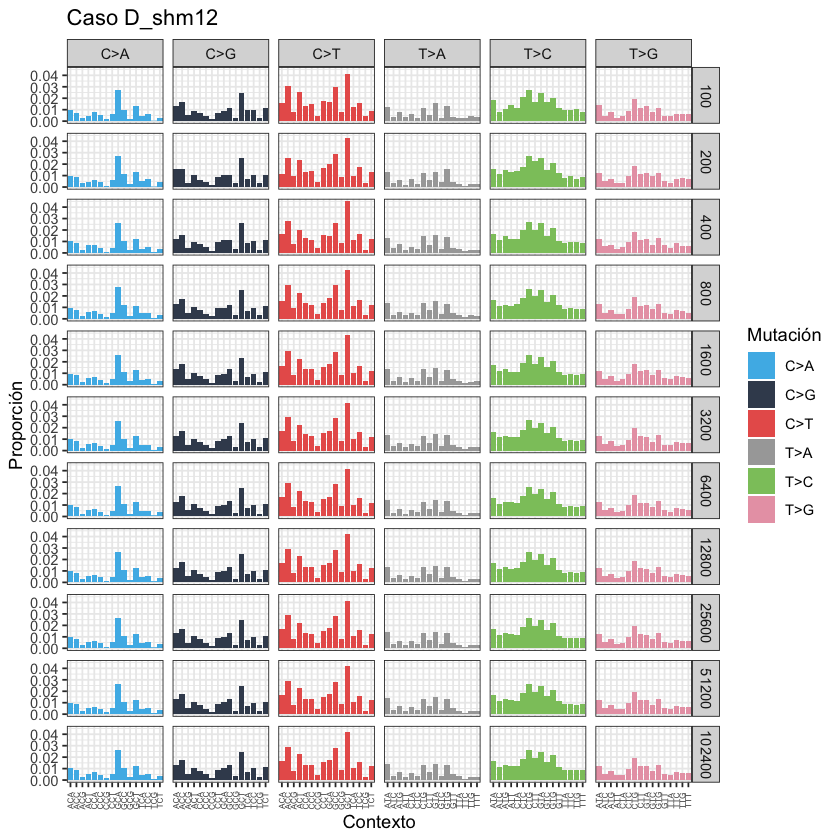

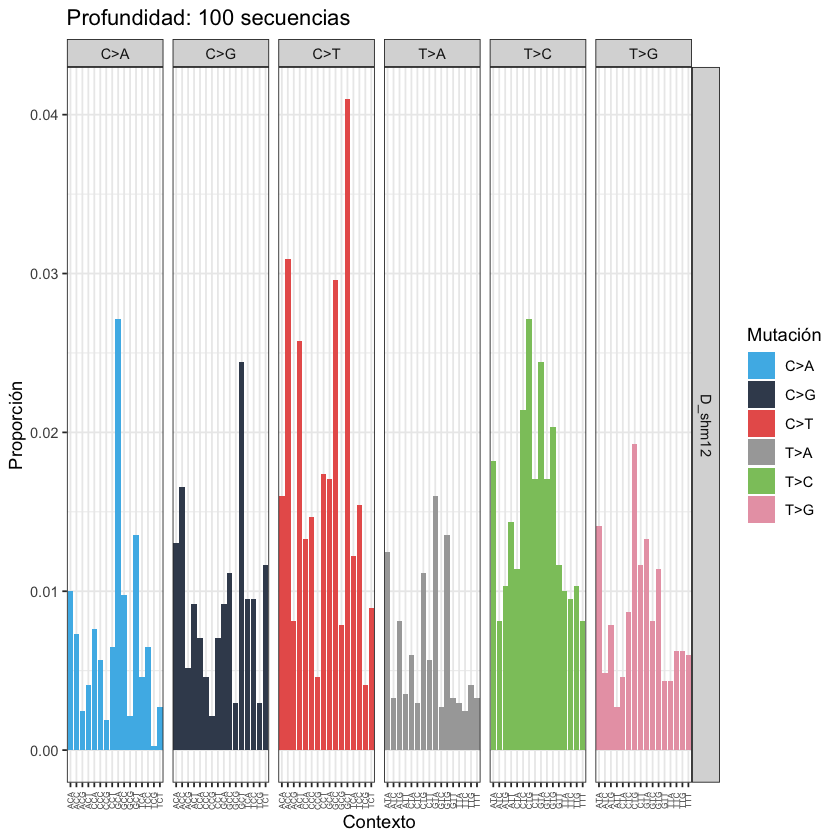

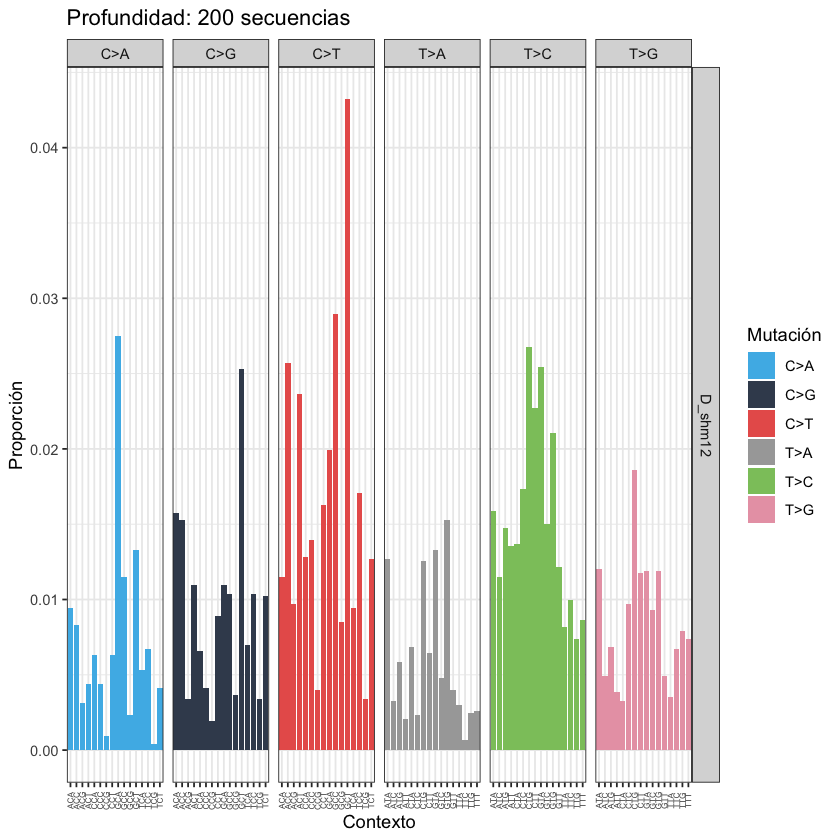

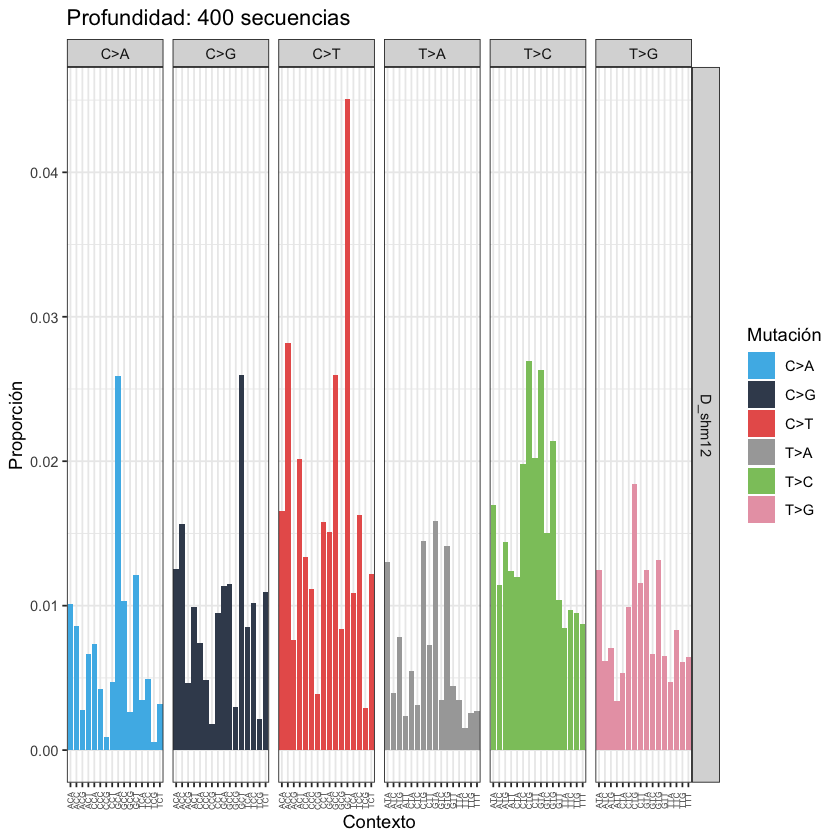

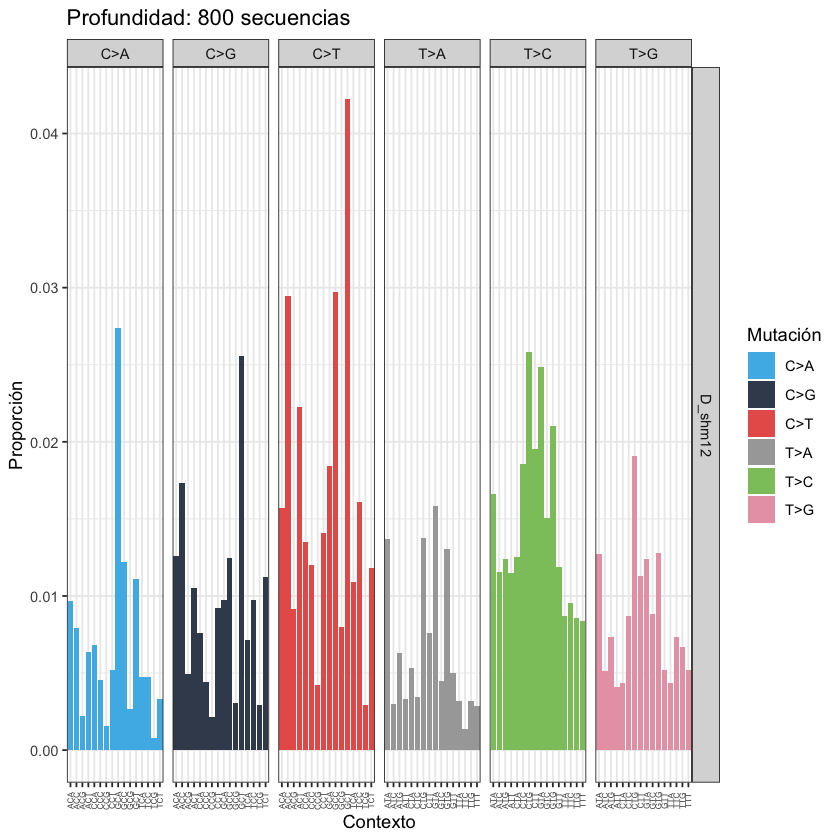

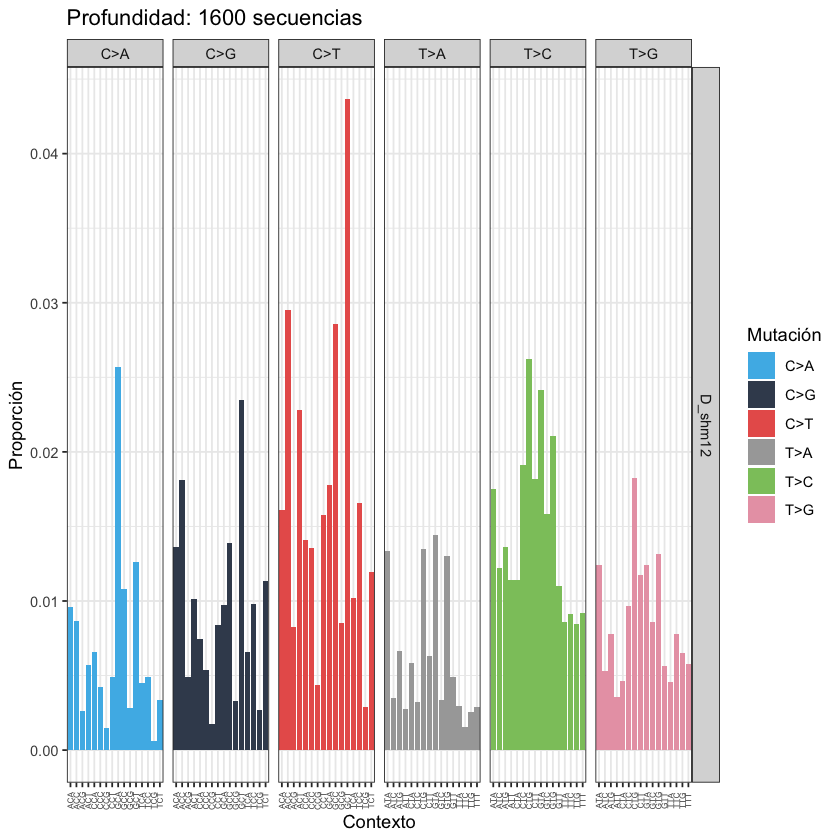

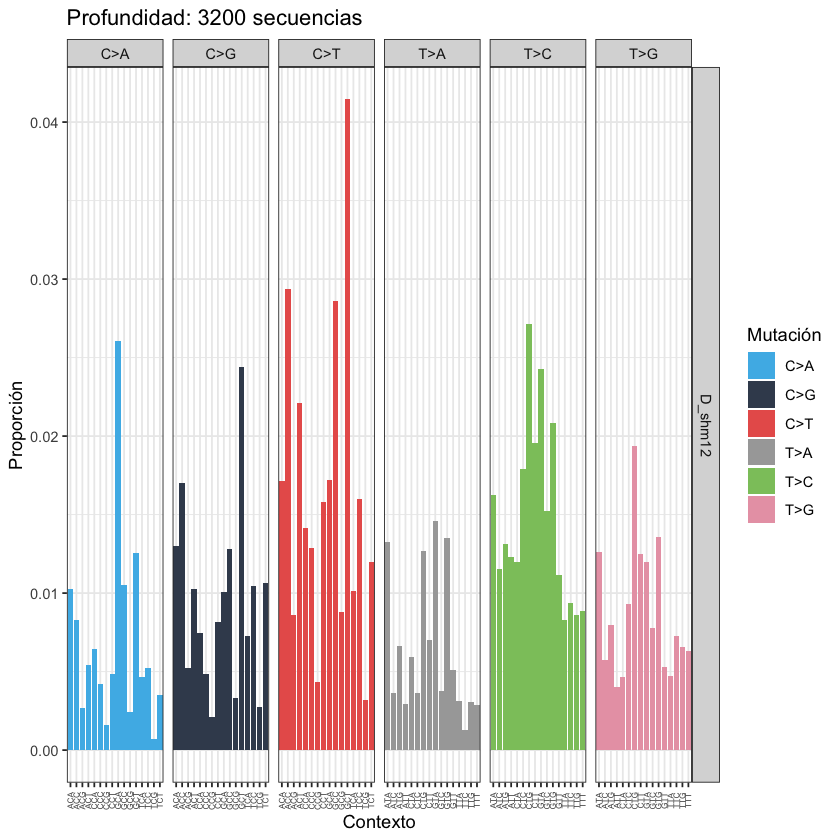

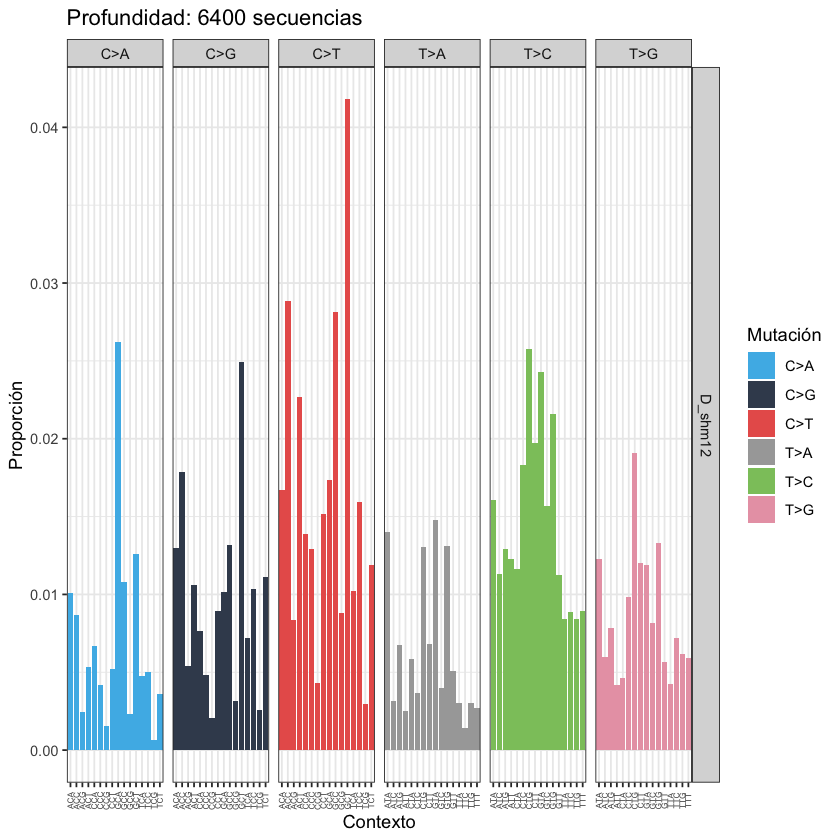

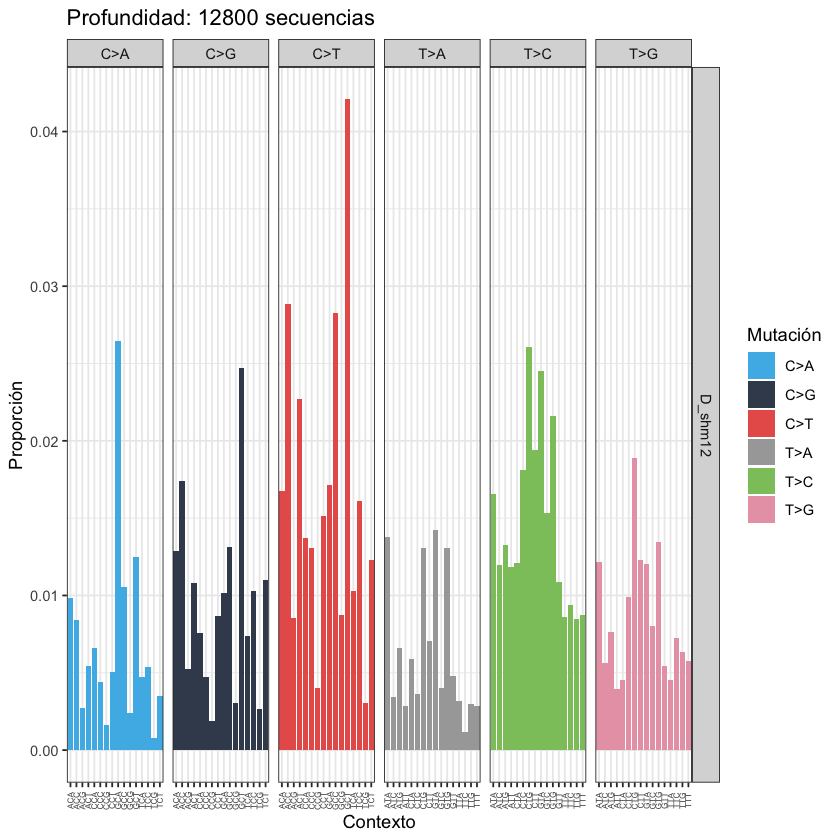

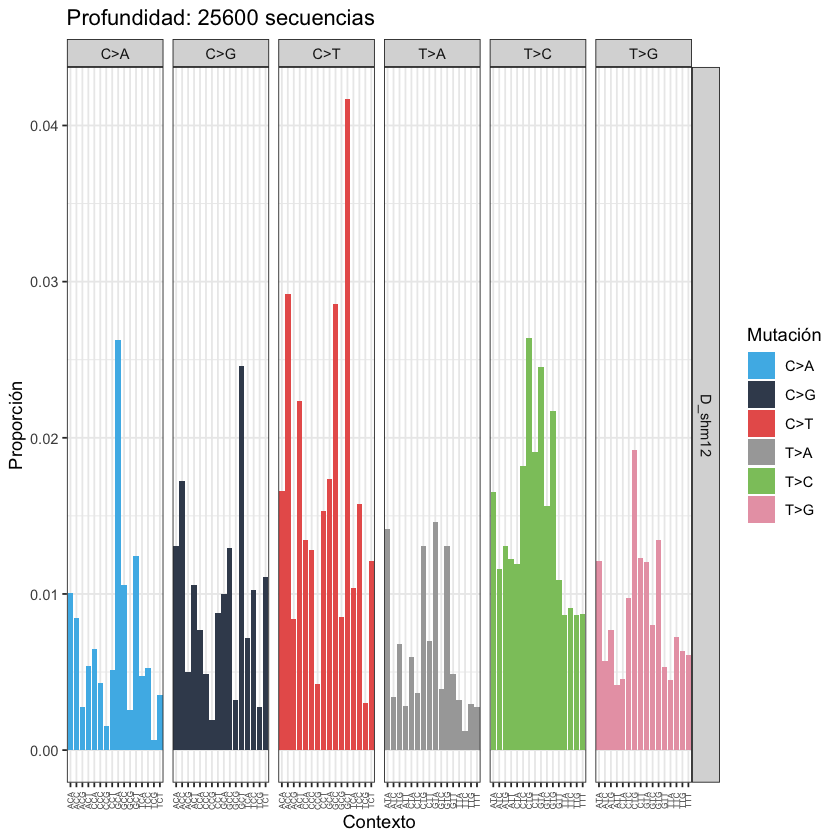

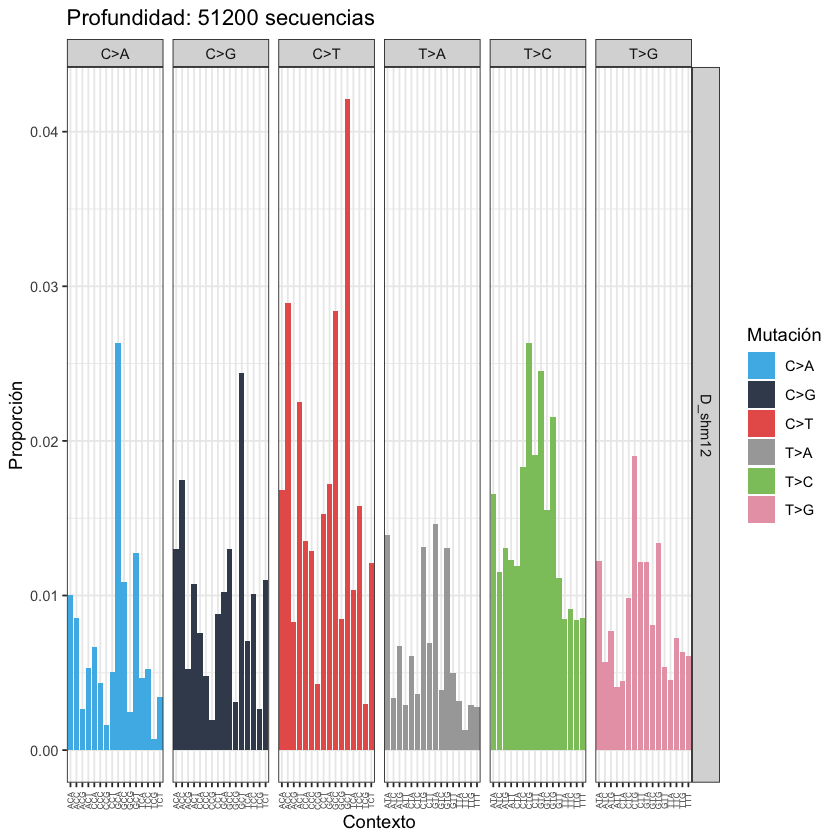

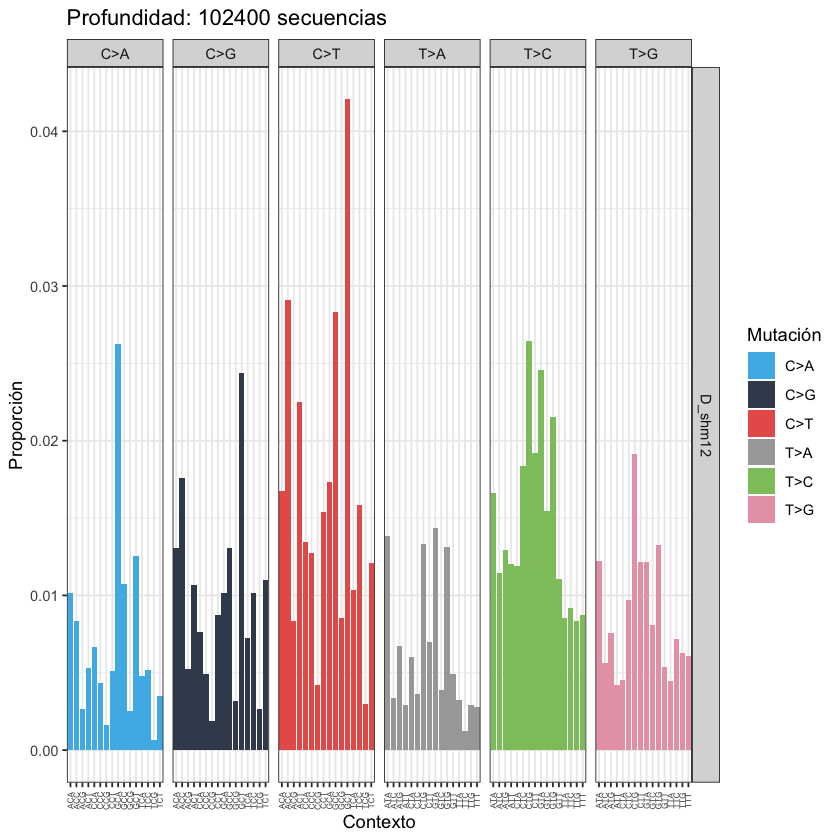

In [1]:
#!/usr/bin/env Rscript
# Perfiles de mutación tipo signature SBS96, usando trinucleótidos y colapsando a la base pirimidina de referencia (C o T), como en COSMIC.
# Salida: figuras/por_caso/*.png (facet = profundidad) y figuras/por_profundidad/*.png (facet = caso).

library(tidyverse)

revcomp <- function(x) chartr("ACGT", "TGCA", stringi::stri_reverse(x))

plot_sbs <- function(df, filas, titulo) {
  ggplot(df, aes(tri, prop, fill = tipo)) +
    geom_col() +
    scale_fill_manual(values = paleta) +
    facet_grid(rows = vars({{ filas }}), cols = vars(tipo), scales = "free_x") +
    labs(title = titulo, x = "Contexto", y = "Proporci\u00F3n", fill = "Mutaci\u00F3n") +
    theme_bw() +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, size = 5))
}


paleta <- c(
  "C>A" = "#4DB8E8", "C>G" = "#3D4A5C", "C>T" = "#E8605A",
  "T>A" = "#A8A8A8", "T>C" = "#8CC56B", "T>G" = "#E8A3B3"
)

d <- read_csv("/Users/catg/Desktop/SOFIAC/Gitsofia/tesisbioinf-sofia/results/signatures/sin_colapsar/tabla_motif_mutacion_D_shm12.csv",
              show_col_types = FALSE)

sbs <- d |>
  mutate(
    tri = substr(motif, 2, 4),
    ref = substr(mutacion, 1, 1),
    alt = substr(mutacion, 3, 3),
    purina = ref %in% c("A", "G"),
    tri = if_else(purina, revcomp(tri), tri),
    ref = if_else(purina, chartr("AG", "TC", ref), ref),
    alt = if_else(purina, chartr("ACGT", "TGCA", alt), alt),
    tipo = paste0(ref, ">", alt)
  ) |>
  count(escenario, profundidad, tipo, tri, wt = conteo, name = "n")

# completa las combinaciones faltantes con 0
clases <- expand_grid(
  tipo = c("C>A", "C>G", "C>T", "T>A", "T>C", "T>G"),
  b5 = c("A", "C", "G", "T"),
  b3 = c("A", "C", "G", "T")
) |>
  mutate(tri = paste0(b5, substr(tipo, 1, 1), b3)) |>
  select(tipo, tri)

sbs <- sbs |>
  right_join(expand_grid(distinct(sbs, escenario, profundidad), clases),
    by = c("escenario", "profundidad", "tipo", "tri")
  ) |>
  mutate(n = replace_na(n, 0)) |>
  group_by(escenario, profundidad) |>
  mutate(prop = n / sum(n)) |>
  ungroup() |>
  mutate(
    tri = factor(tri, levels = unique(clases$tri)),
    profundidad = factor(profundidad, levels = sort(unique(profundidad)))
  )

dir_fig <- "/Users/catg/Desktop/SOFIAC/Gitsofia/tesisbioinf-sofia/results/signatures/figuras"
dir.create(file.path(dir_fig, "por_caso"), recursive = TRUE, showWarnings = FALSE)
dir.create(file.path(dir_fig, "por_profundidad"), recursive = TRUE, showWarnings = FALSE)

# 1) una figura por caso, facet = profundidad
for (esc in unique(sbs$escenario)) {
  df <- filter(sbs, escenario == esc)
  g <- plot_sbs(df, profundidad, paste("Caso", esc))
  ggsave(file.path(dir_fig, "por_caso", paste0("sbs96_caso_", esc, ".png")),
    g,
    width = 10, height = 1 + 0.9 * n_distinct(df$profundidad), dpi = 200
  )
  print(g)
}

# 2) una figura por profundidad, facet = caso
for (p in levels(sbs$profundidad)) {
  df <- filter(sbs, profundidad == p)
  g <- plot_sbs(df, escenario, paste("Profundidad:", p, "secuencias"))
  ggsave(file.path(dir_fig, "por_profundidad", paste0("sbs96_prof_", p, ".png")),
    g,
    width = 10, height = 1 + 1.2 * n_distinct(df$escenario), dpi = 200
  )
  print(g)
}